# 02. Exploratory Data Analysis

Khám phá xu hướng churn và phân bổ variane.
1. Vẽ biểu đồ phân phối các biến số
2. Phân tích mối quan hệ giữa biến độc lập và biến mục tiêu Churn
3. Vẽ biểu đồ boxplot, bar chart cho các biến danh pháp
4. Tính ma trận tương quan (correlation matrix)
5. Phân tích churn rate theo từng phân nhóm

In [8]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_excel('../data/raw/churn_prediction.xlsx')
df.head()


,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,52869,0,20.0,Mobile Phone,3,7.0,E wallet,Female,4.0,4,Fashion,5,Married,3,0,26.0,5.0,16.0,NaN,229.53
1,52942,0,13.0,Computer,1,9.0,Cash on Delivery,Female,4.0,4,Fashion,3,Single,2,0,26.0,11.0,NaN,9.0,234.38
2,52972,0,16.0,Mobile Phone,3,7.0,Debit Card,Male,3.0,4,Laptop & Accessory,3,Divorced,3,0,26.0,5.0,12.0,7.0,174.07
3,53125,0,5.0,Mobile Phone,1,16.0,Debit Card,Male,3.0,4,Fashion,4,Married,3,0,26.0,2.0,2.0,9.0,231.48
4,53367,0,9.0,Mobile Phone,1,28.0,Debit Card,Female,3.0,4,Laptop & Accessory,2,Divorced,3,1,26.0,1.0,2.0,8.0,165.14


### Phân phối biến số (Numerical Distribution)

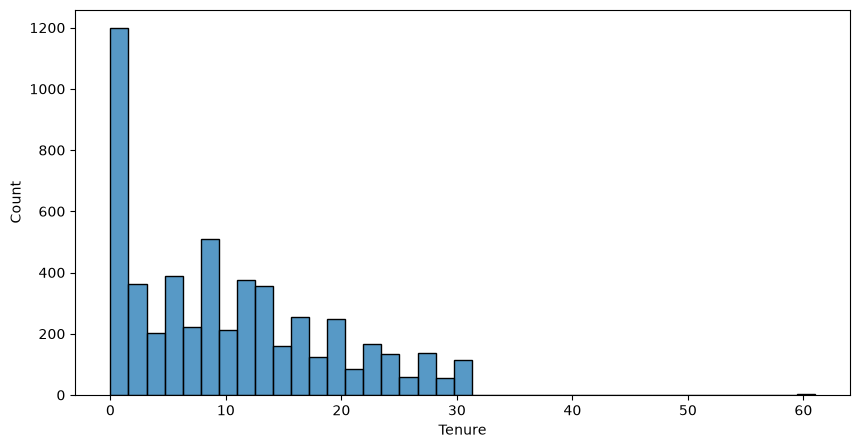

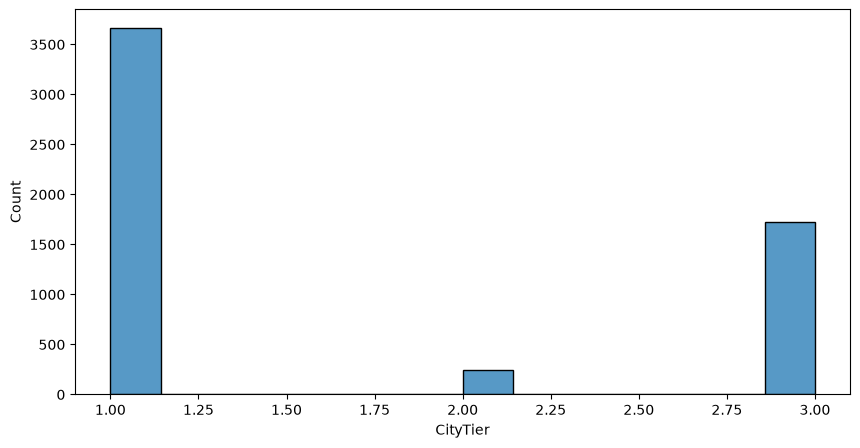

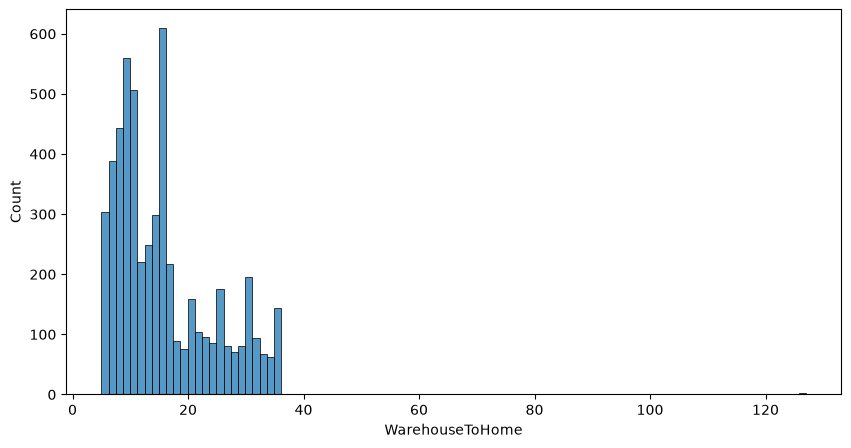

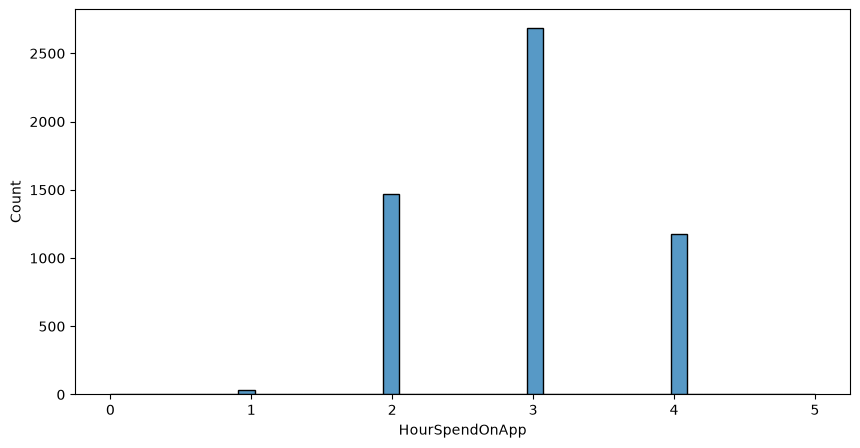

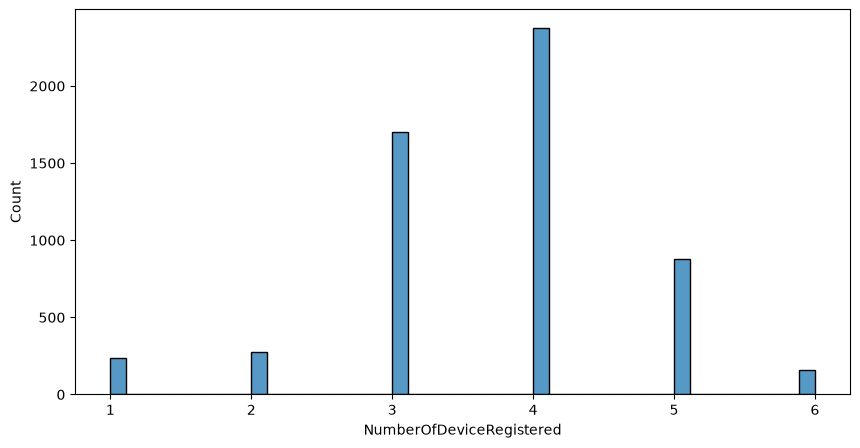

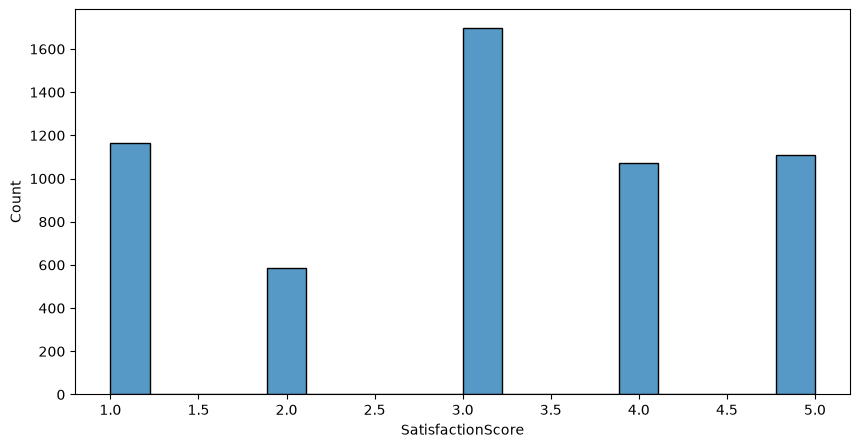

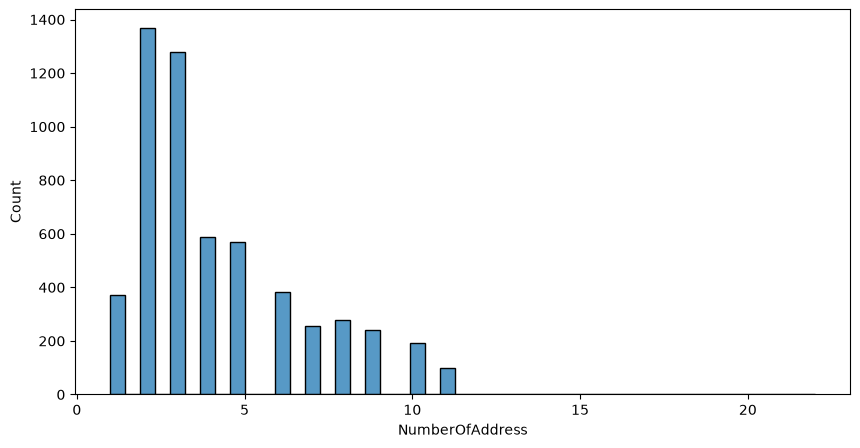

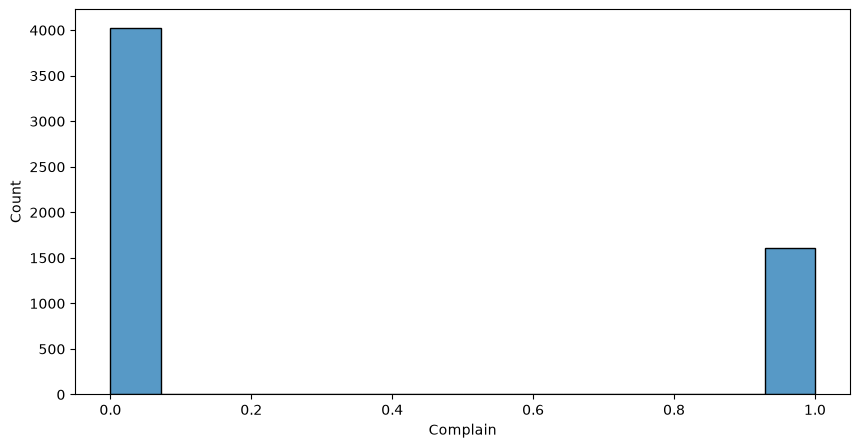

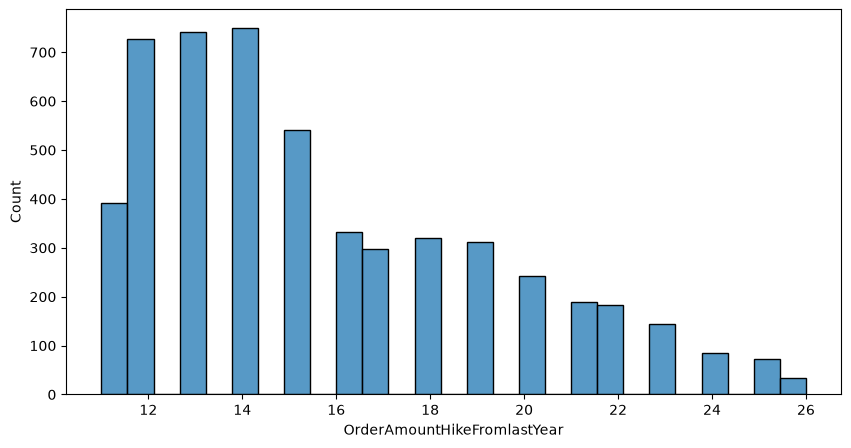

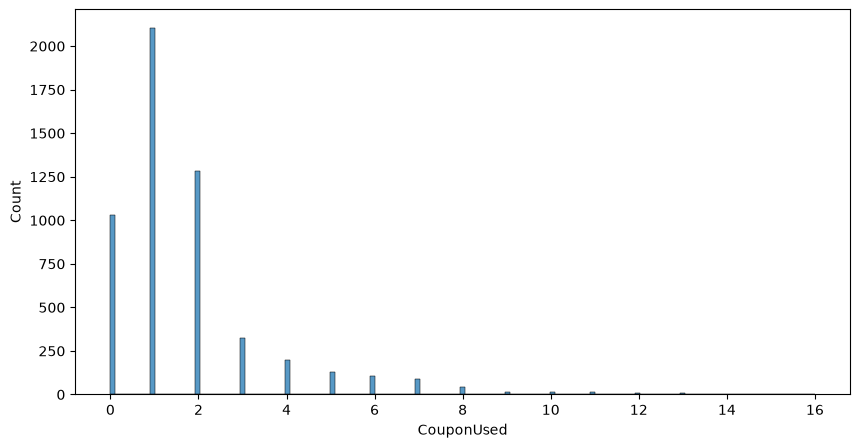

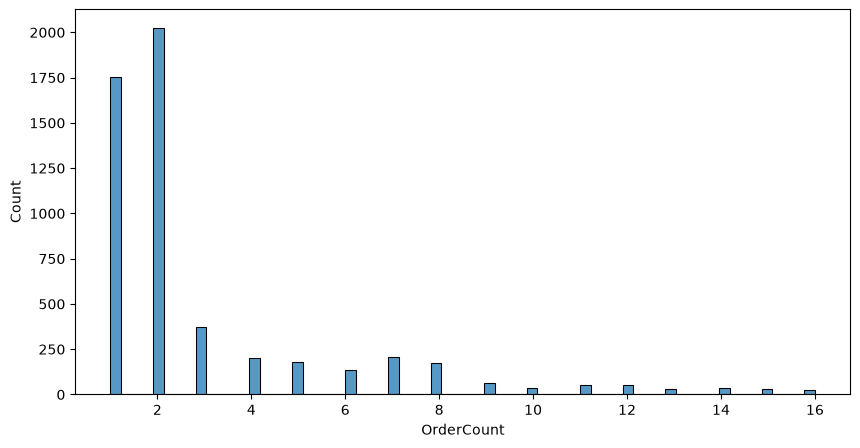

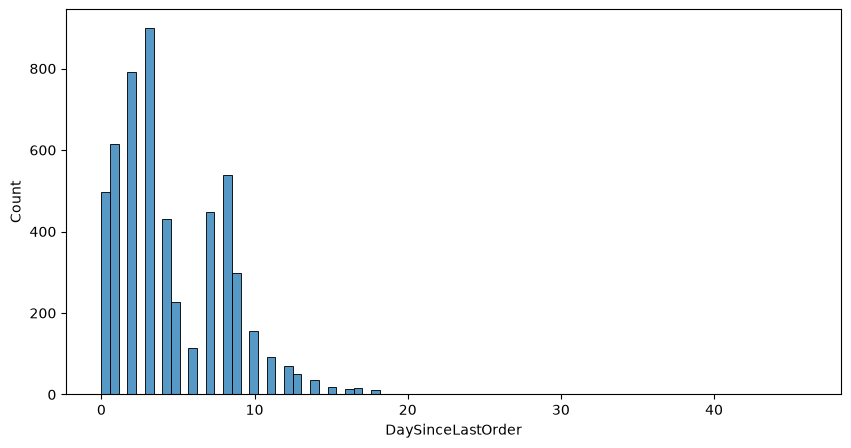

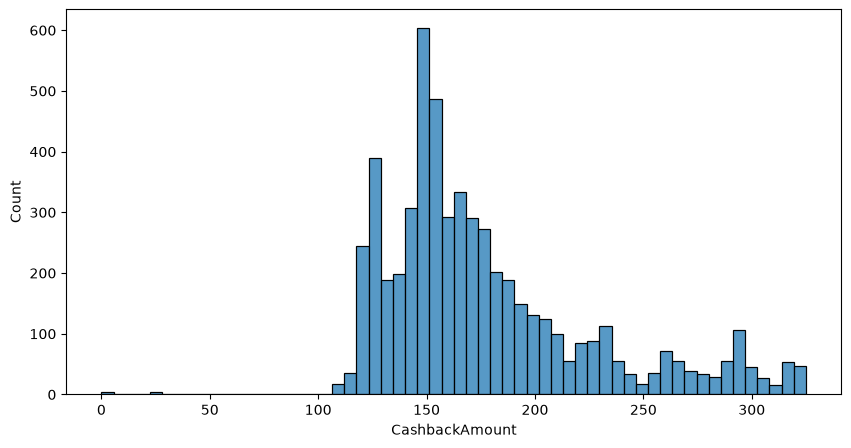

In [18]:
# Lấy danh sách các cột số (loại trừ CustomerID và Churn)
numerical_cols = df.select_dtypes(include='number').columns.tolist()
numerical_cols.remove('CustomerID')
numerical_cols.remove('Churn')

# Vẽ biểu đồ biểu diễn phân phối từng biến số
for col in numerical_cols:
    plt.figure(figsize=(10, 5))
    sns.histplot(df[col])
    plt.show()

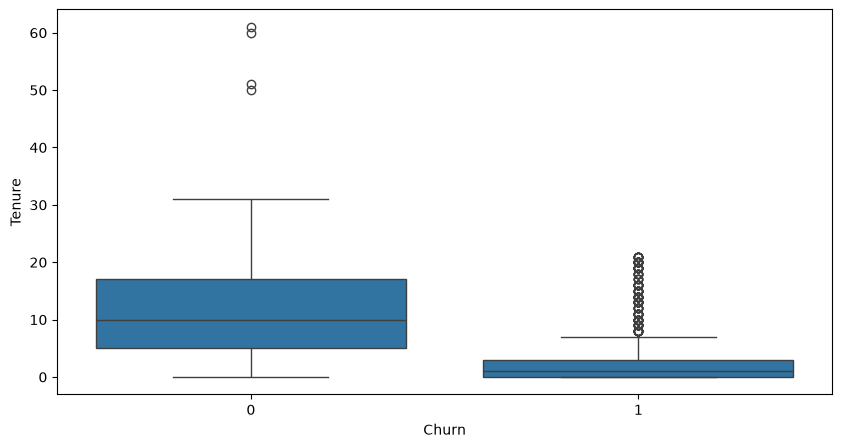

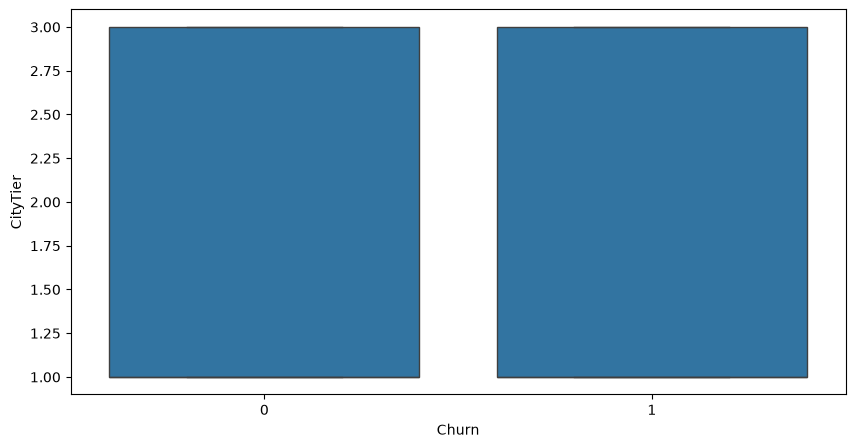

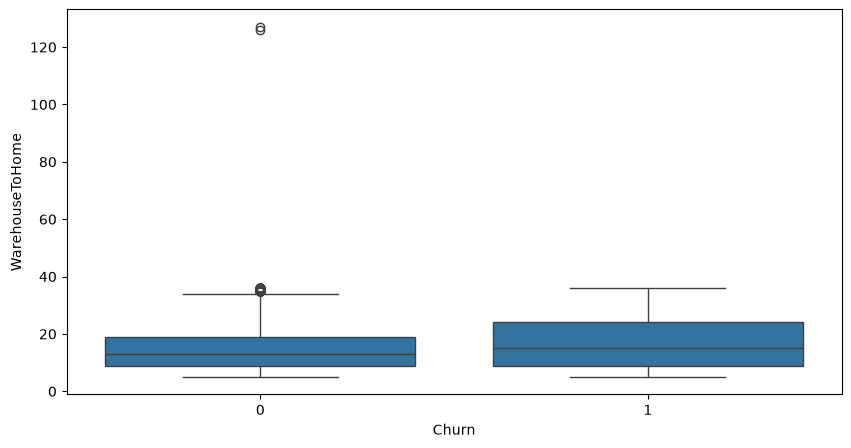

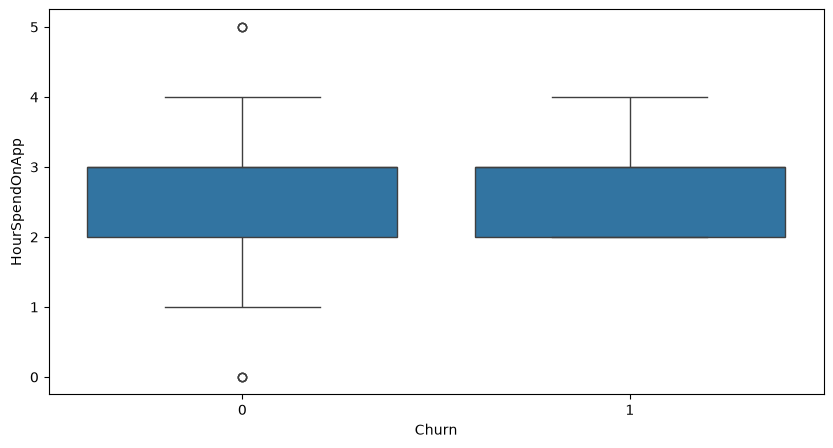

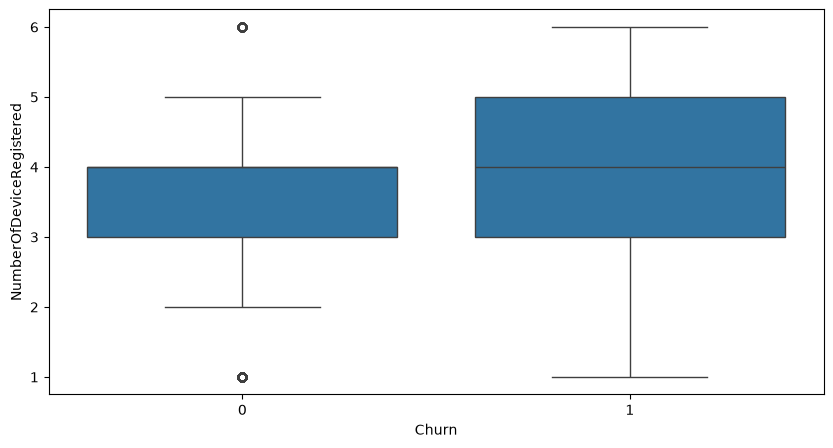

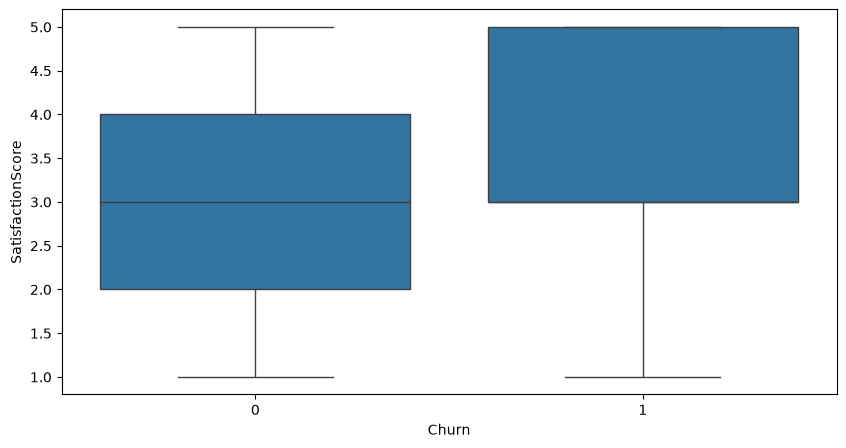

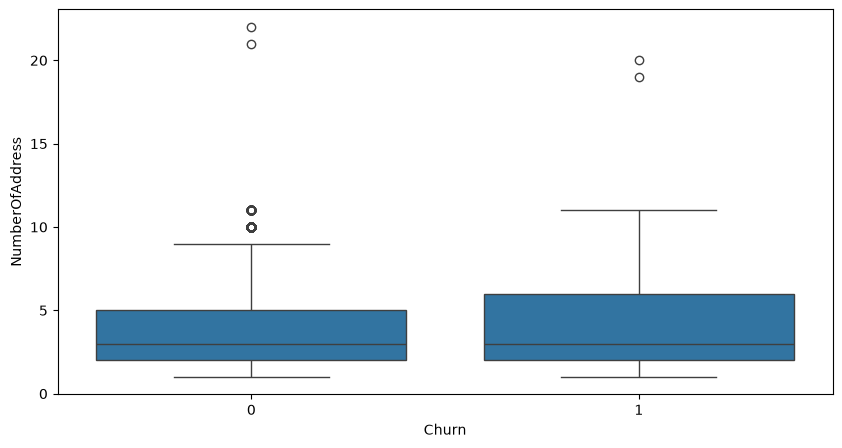

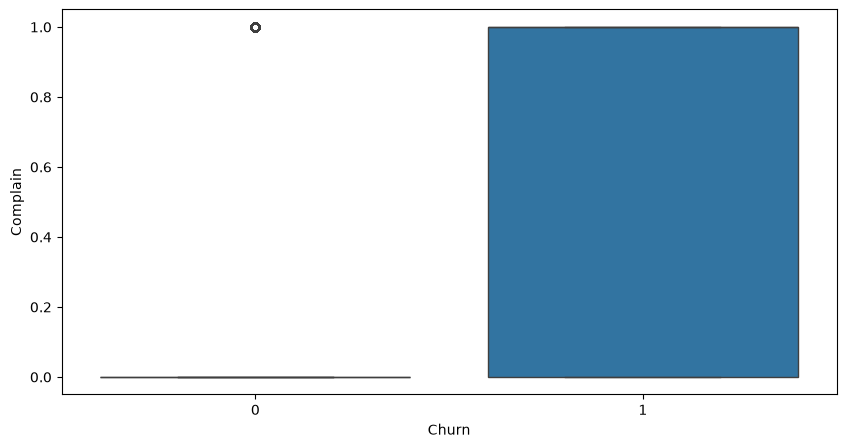

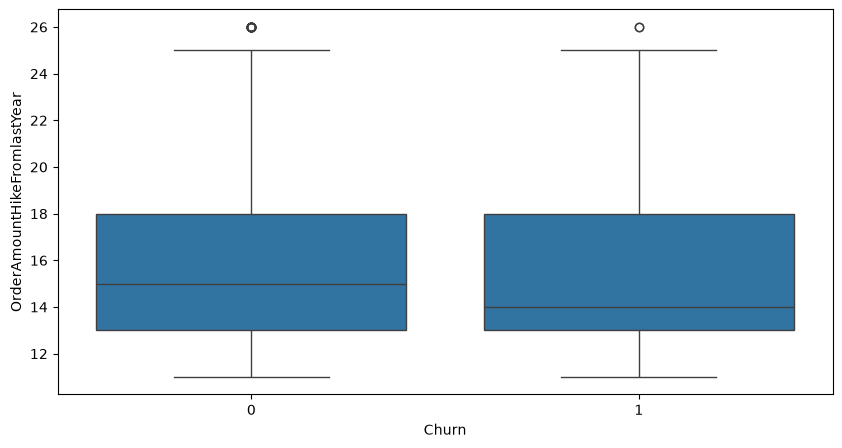

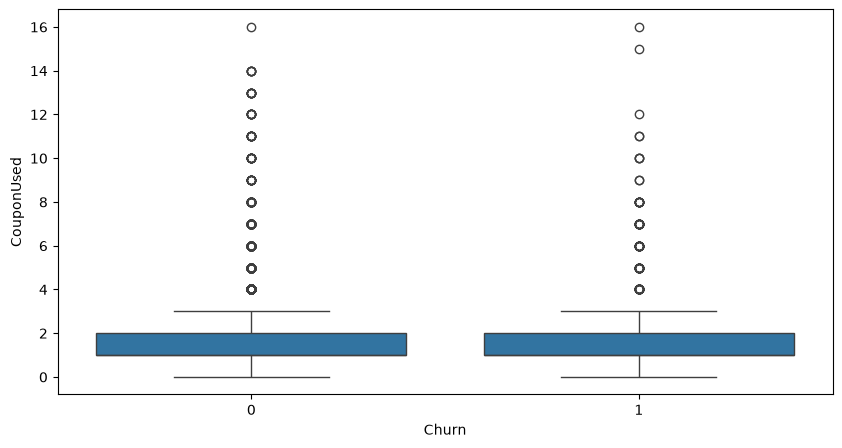

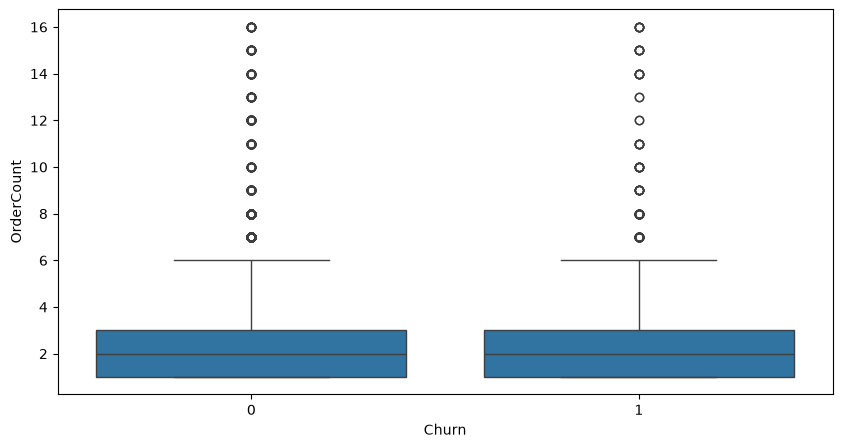

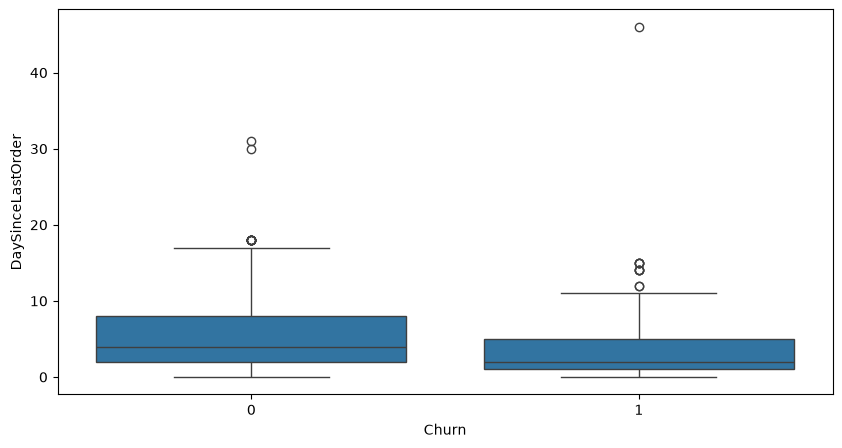

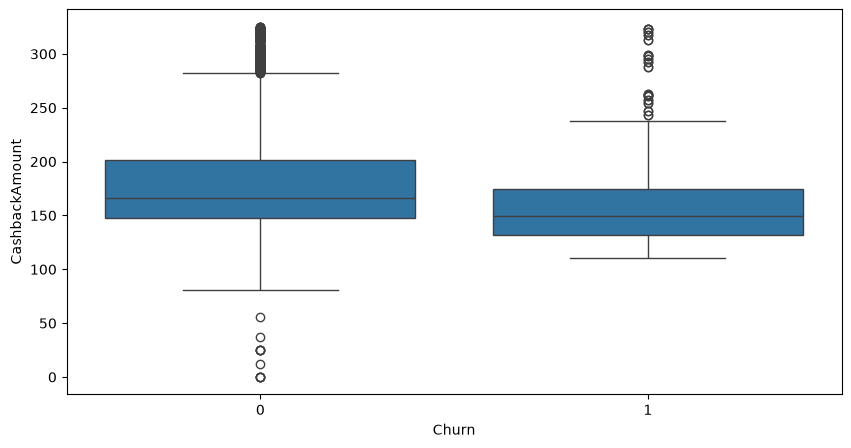

In [19]:
# Vẽ biểu đổ phân phối các biến số so với biến mục tiêu 'Churn'
for col in numerical_cols:
    plt.figure(figsize=(10, 5))
    sns.boxplot(x='Churn', y=col, data=df)
    plt.show()


### Phân phối biến danh pháp (Categorical Distribution)

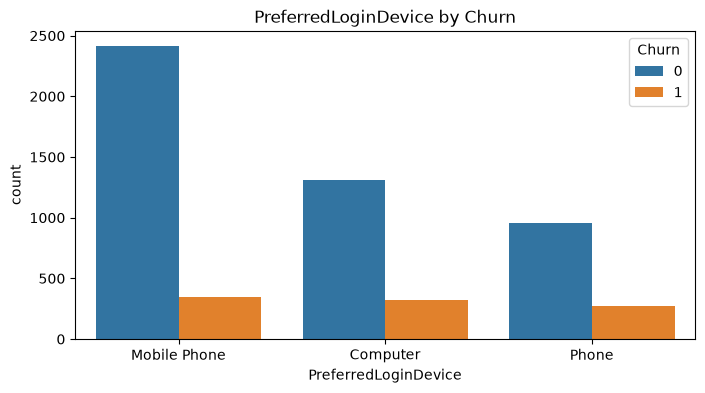

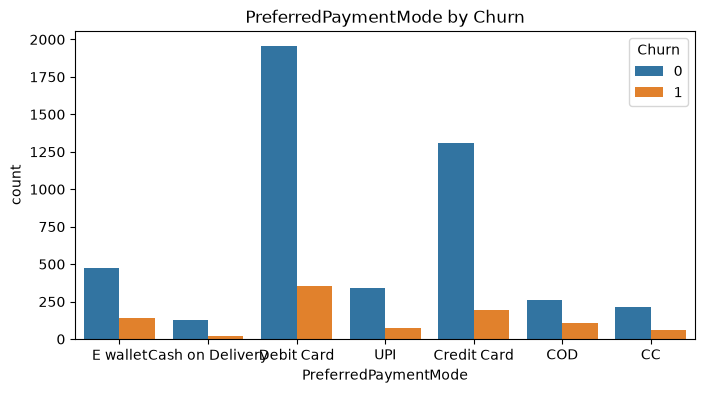

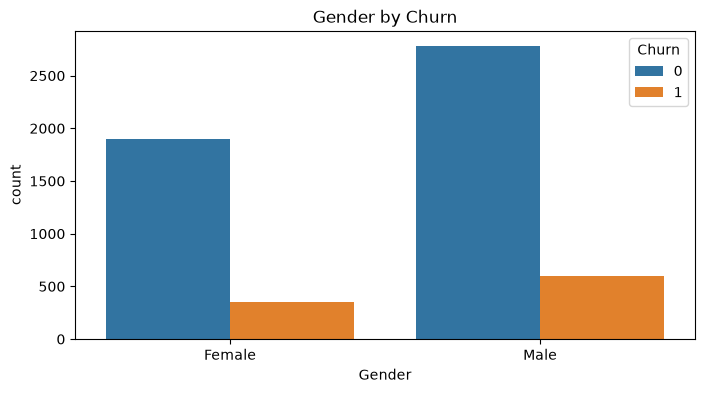

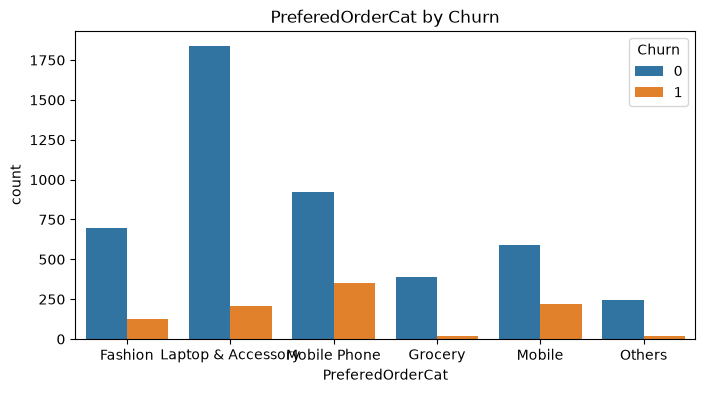

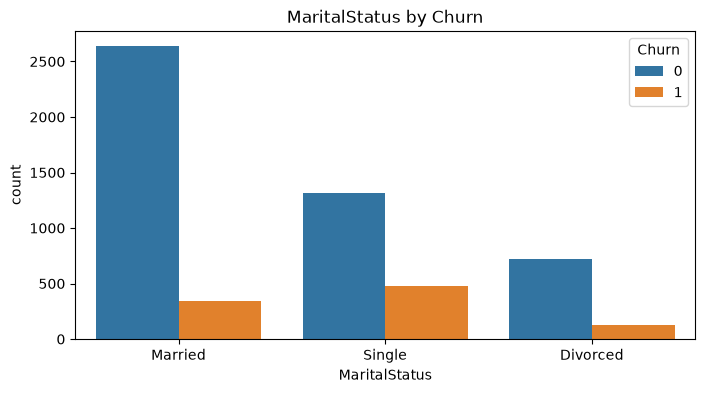

In [ ]:
# lấy danh sách các cột định tính
categorical_cols = df.select_dtypes(include=['object', 'str']).columns.tolist()

# Vẽ biểu đồ phân phối các biến định tính so với biến mục tiêu 'Churn'
for col in categorical_cols:
    if col in df.columns:
        plt.figure(figsize=(8, 4))
        sns.countplot(x=col, hue='Churn', data=df)
        plt.title(f'{col} by Churn')
        plt.show()

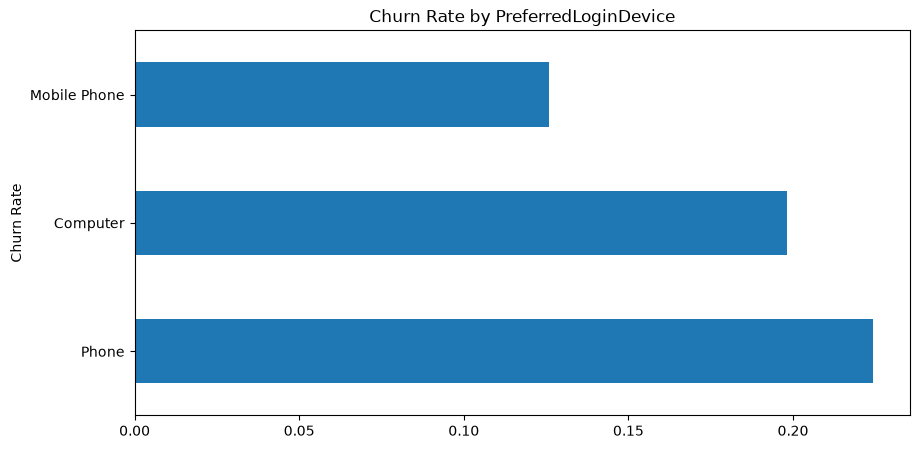

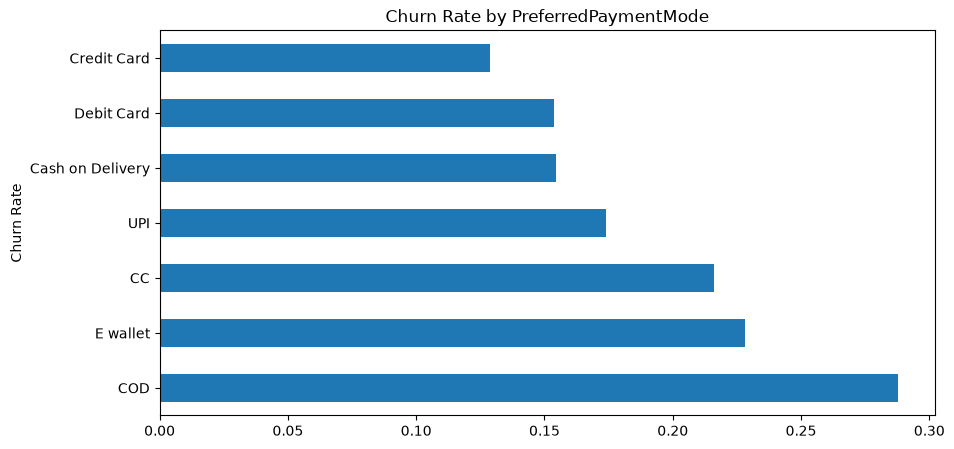

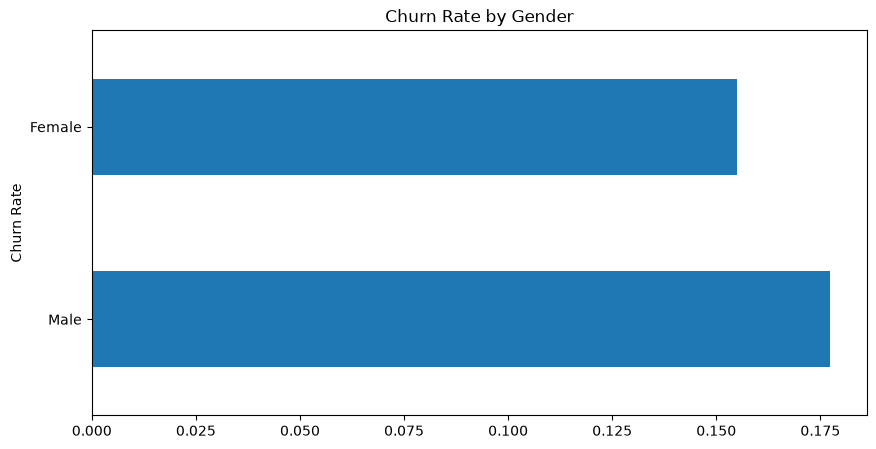

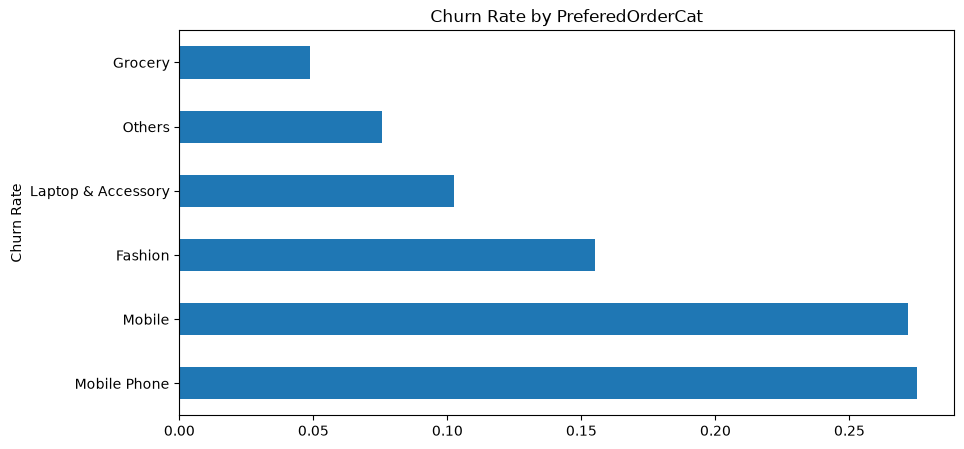

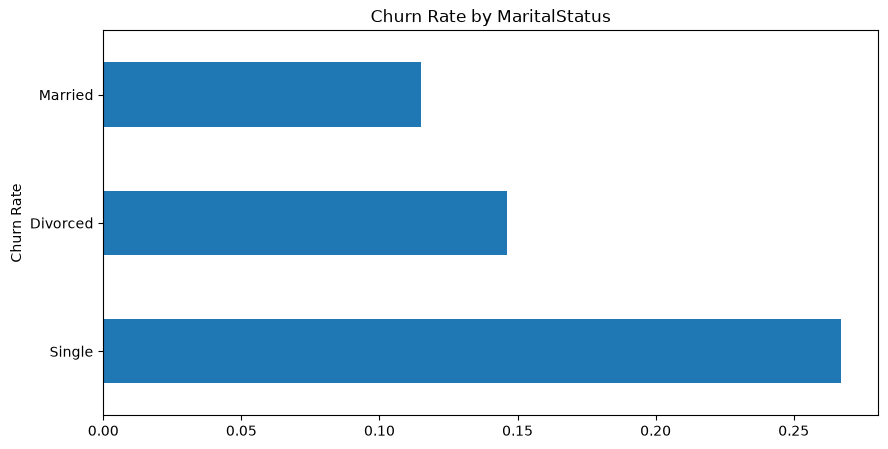

In [21]:
# Vẽ churn rate cho từng biến định tính
for col in categorical_cols:
    if col in categorical_cols:
        # tính churn rate cho từng nhóm
        churn_rate = df.groupby(col)['Churn'].mean().sort_values(ascending=False)
        plt.figure(figsize=(10, 5))
        churn_rate.plot(kind='barh')
        plt.title(f'Churn Rate by {col}')
        plt.ylabel('Churn Rate')
        plt.show()

### Ma trận tương quan (Correlation Matrix)

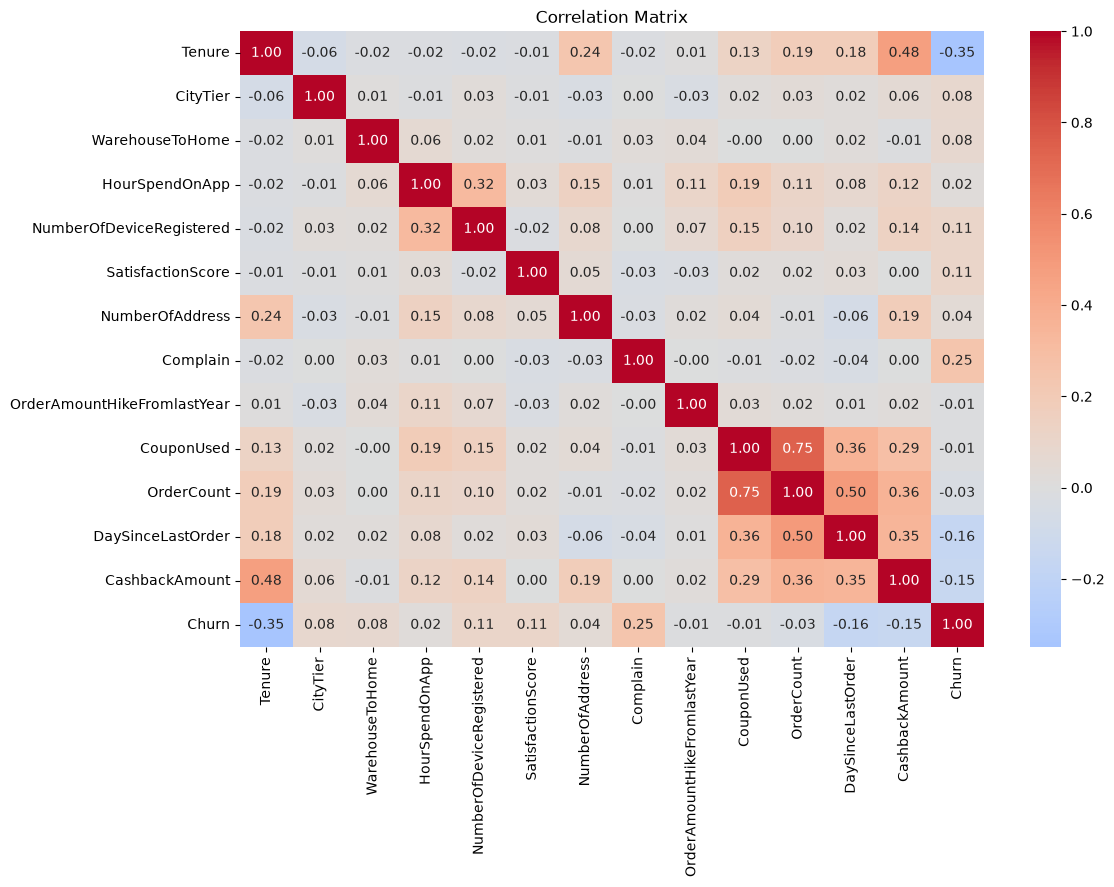

Complain                       0.250188
NumberOfDeviceRegistered       0.107939
SatisfactionScore              0.105481
CityTier                       0.084703
WarehouseToHome                0.076630
NumberOfAddress                0.043931
HourSpendOnApp                 0.018675
CouponUsed                    -0.008264
OrderAmountHikeFromlastYear   -0.010058
OrderCount                    -0.028697
CashbackAmount                -0.154118
DaySinceLastOrder             -0.160757
Tenure                        -0.349408
Name: Churn, dtype: float64

In [22]:
# Tính ma trận tương quan giữa các biến số
corr_matrix = df[numerical_cols + ['Churn']].corr()
# Vẽ heatmap của ma trận tương quan
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", center=0)
plt.title('Correlation Matrix')
plt.show()

# Mức độ tương quan
churn_corr = corr_matrix['Churn'].drop('Churn').sort_values(ascending=False)
churn_corr

### Kết luận EDA

Từ quá trình khám phá dữ liệu, có thể rút ra các nhận xét quan trọng sau:

- Biến có mối liên hệ mạnh nhất với Churn là `Tenure`, với hệ số tương quan âm khá rõ (-0.349). Điều này cho thấy khách hàng ở lại lâu hơn có xu hướng ít rời bỏ dịch vụ hơn, trong khi khách hàng mới hoặc có thời gian gắn bó ngắn thường có nguy cơ churn cao hơn.
- `Complain` cũng là yếu tố đáng chú ý, với tương quan dương 0.250 so với Churn. Khách hàng có khiếu nại hoặc gặp sự cố dịch vụ có xu hướng rời bỏ cao hơn.
- Các biến như `DaySinceLastOrder` (-0.161) và `CashbackAmount` (-0.154) cho thấy người dùng ít tương tác hoặc nhận được ít hoàn tiền/khuyến mãi có thể có nguy cơ rời đi cao hơn, nhưng mức độ ảnh hưởng yếu hơn so với `Tenure` và `Complain`.
- Các biến số khác như `CityTier`, `WarehouseToHome`, `SatisfactionScore`, `NumberOfDeviceRegistered` có tương quan thấp đến trung bình với Churn, cho thấy churn không phụ thuộc vào một yếu tố duy nhất mà là kết quả của nhiều yếu tố cùng tác động.
- Phân tích theo nhóm cho thấy `MaritalStatus` có sự khác biệt rõ: nhóm `Single` có tỷ lệ churn cao nhất (~26.7%), tiếp đến là `Divorced` (~14.6%) và `Married` (~11.5%). Nhóm khách hàng độc thân có nguy cơ rời bỏ cao hơn so với nhóm đã kết hôn.
- Tổng quan, khách hàng có thời gian gắn bó ngắn, có khiếu nại, ít tương tác, và thuộc nhóm có churn cao hơn là những đối tượng cần được ưu tiên theo dõi và can thiệp.
- Vì các biến đều có mức độ ảnh hưởng khác nhau và không tồn tại một dấu hiệu duy nhất quyết định churn, bước tiếp theo nên là xây dựng mô hình dự đoán, ưu tiên các biến quan trọng theo phương pháp hồi quy/logistic, feature importance hoặc model-based selection để tối ưu hóa dự báo.